In [1]:
import glob
import pathlib

import datasets
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader
from utils.distance import (
    DistanceProbe,
    DistanceProbeDataset,
    LazyDistanceProbeDataset,
    distance_collate,
    distance_loss,
)

best = glob.glob(
    str(pathlib.Path("..").resolve().absolute() / "probes/distance/l*-r512/best.pt")
)
best = sorted(best, key=lambda x: int(x.split("/")[8].split("-")[0][1:]))

hf_dataset = datasets.load_from_disk("../dataset/Qwen/Qwen2.5-Coder-0.5B/").with_format(
    "numpy"
)


device = torch.device("mps")


def load_probe(path):
    probe = DistanceProbe(896, 512)
    probe.load_state_dict(torch.load(path, weights_only=True))
    probe.eval()
    return probe.to(device)


dataset = LazyDistanceProbeDataset(hf_dataset["test"], None)
probes = [load_probe(path) for path in best]

/Users/hw452/Documents/programming/structural-probe-ast-rewrite/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from tqdm import tqdm

layer_loss = []

for i, probe in enumerate(tqdm(probes)):
    dataset.layer = i
    loader = DataLoader(
        dataset, batch_size=64, shuffle=True, collate_fn=distance_collate
    )
    num_test_batches = len(loader)
    total_test_loss = 0.0
    for hidden, distance, mask in loader:
        hidden = hidden.to(device)
        distance = distance.to(device)
        mask = mask.to(device)

        with torch.no_grad():
            predicted_distance = probe(hidden)

        loss = distance_loss(predicted_distance, distance, mask, reduce="sum")
        total_test_loss += loss

    avg_test_loss = (total_test_loss / len(hf_dataset["test"])).item()
    layer_loss.append(avg_test_loss)

100%|██████████| 25/25 [05:57<00:00, 14.30s/it]


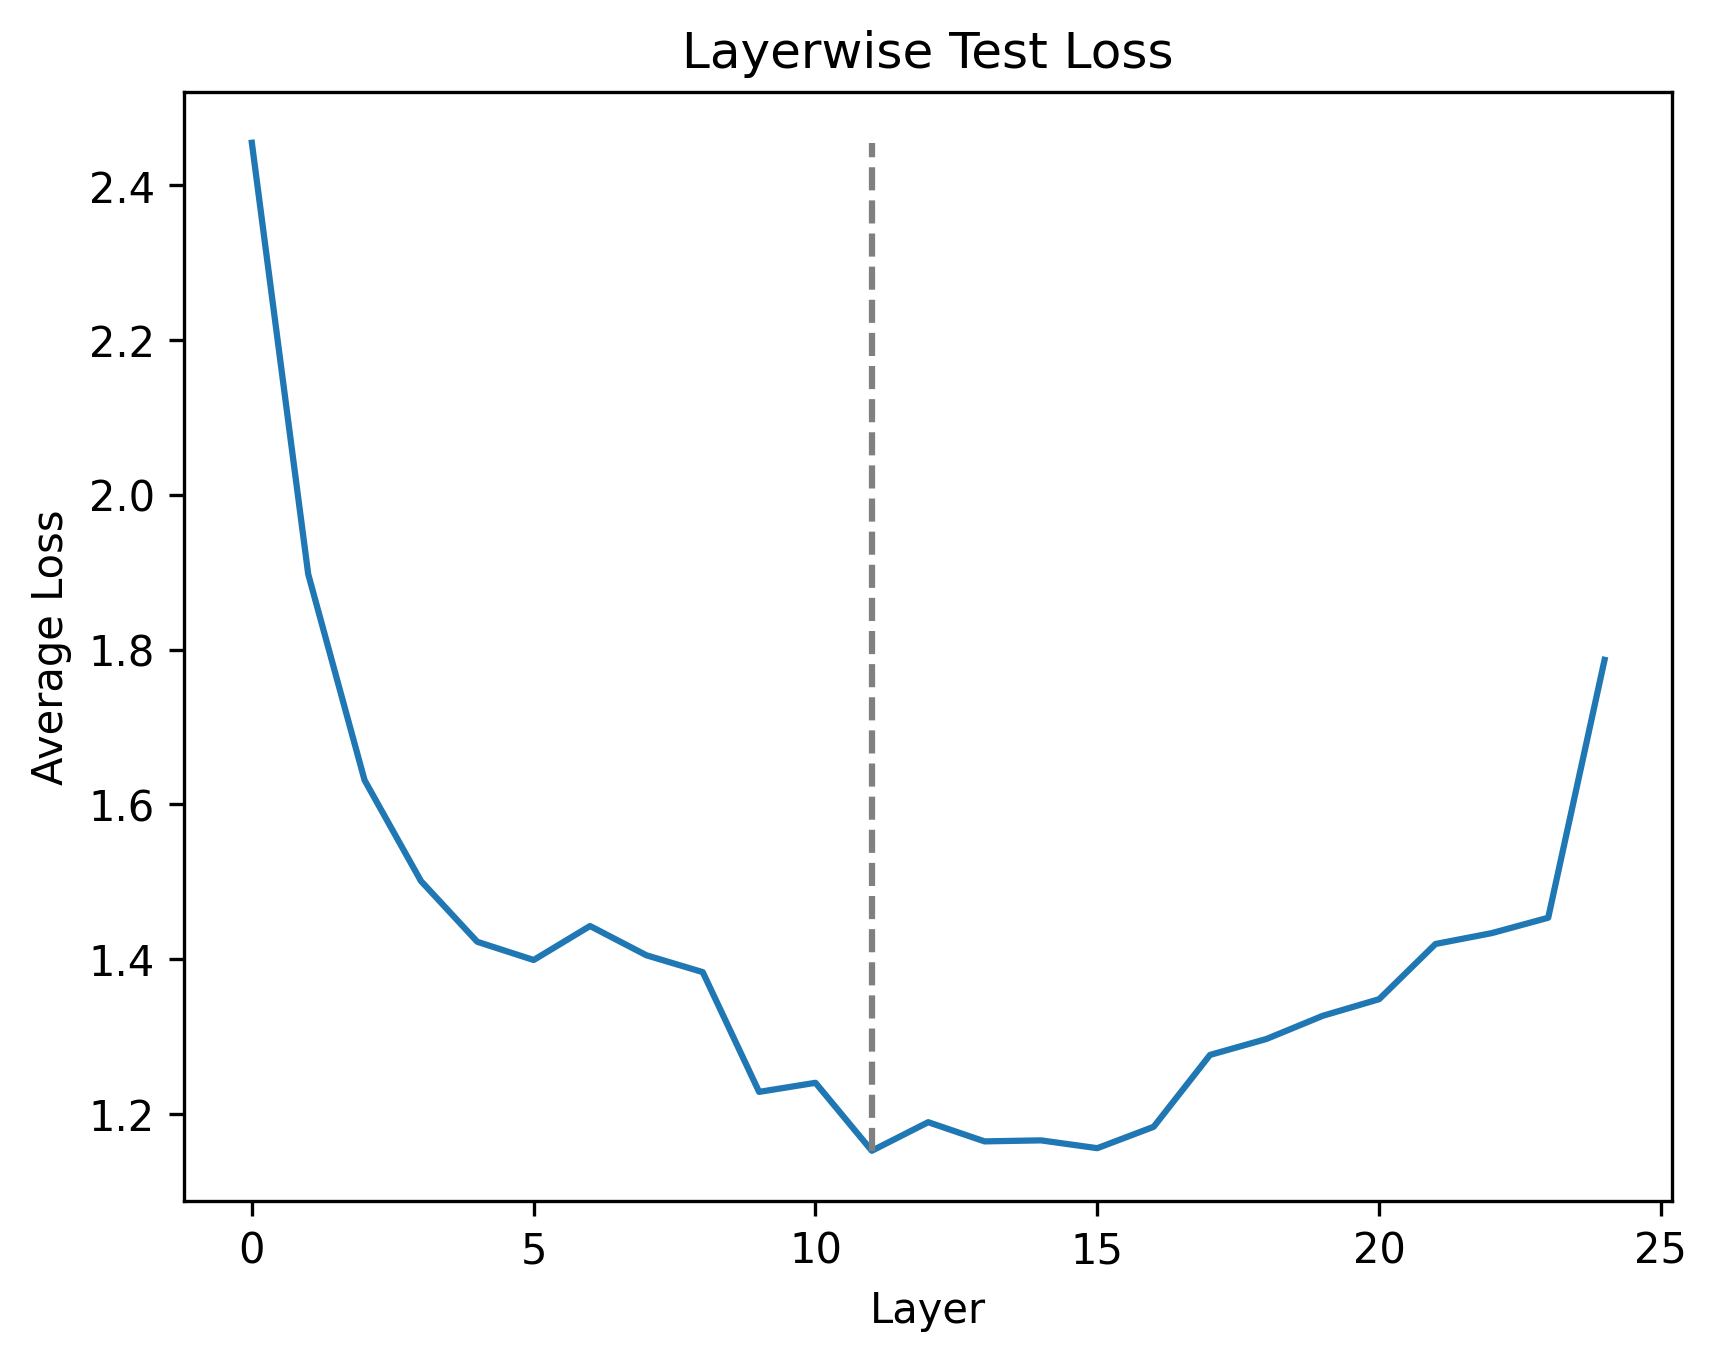

In [3]:
best_layer = np.argmin(layer_loss)
best = probes[best_layer]

plt.figure(dpi=300)
plt.title("Layerwise Test Loss")
plt.plot(layer_loss)
plt.vlines(best_layer, min(layer_loss), max(layer_loss), color="grey", linestyles="--")
plt.xlabel("Layer")
plt.ylabel("Average Loss")
plt.show()

In [4]:
dataset = {}

for language in set(hf_dataset["test"]["language"]):
    hf_subset = hf_dataset["test"].filter(
        lambda example: example["language"] == language
    )

    tmp_dataset = DistanceProbeDataset(hf_subset, layer=best_layer)
    dataset[language] = DataLoader(
        tmp_dataset, batch_size=64, collate_fn=distance_collate
    )


Loading: 100%|██████████| 2/2 [00:01<00:00,  1.69it/s]


In [5]:
{str(l): len(loader.dataset) for l, loader in dataset.items()}

{'rust': 460,
 'javascript': 472,
 'cpp': 423,
 'c': 448,
 'haskell': 555,
 'python': 484,
 'php': 521,
 'java': 522,
 'go': 464}

In [14]:
from collections import defaultdict

results = defaultdict(float)

for language, loader in dataset.items():
    for hidden, distance, mask in loader:
        hidden = hidden.to(device)
        distance = distance.to(device)
        mask = mask.to(device)

        with torch.no_grad():
            predicted_distance = best(hidden)

        results[language] += distance_loss(
            predicted_distance, distance, mask, reduce="sum"
        ).item()

    results[language] /= len(loader.dataset)

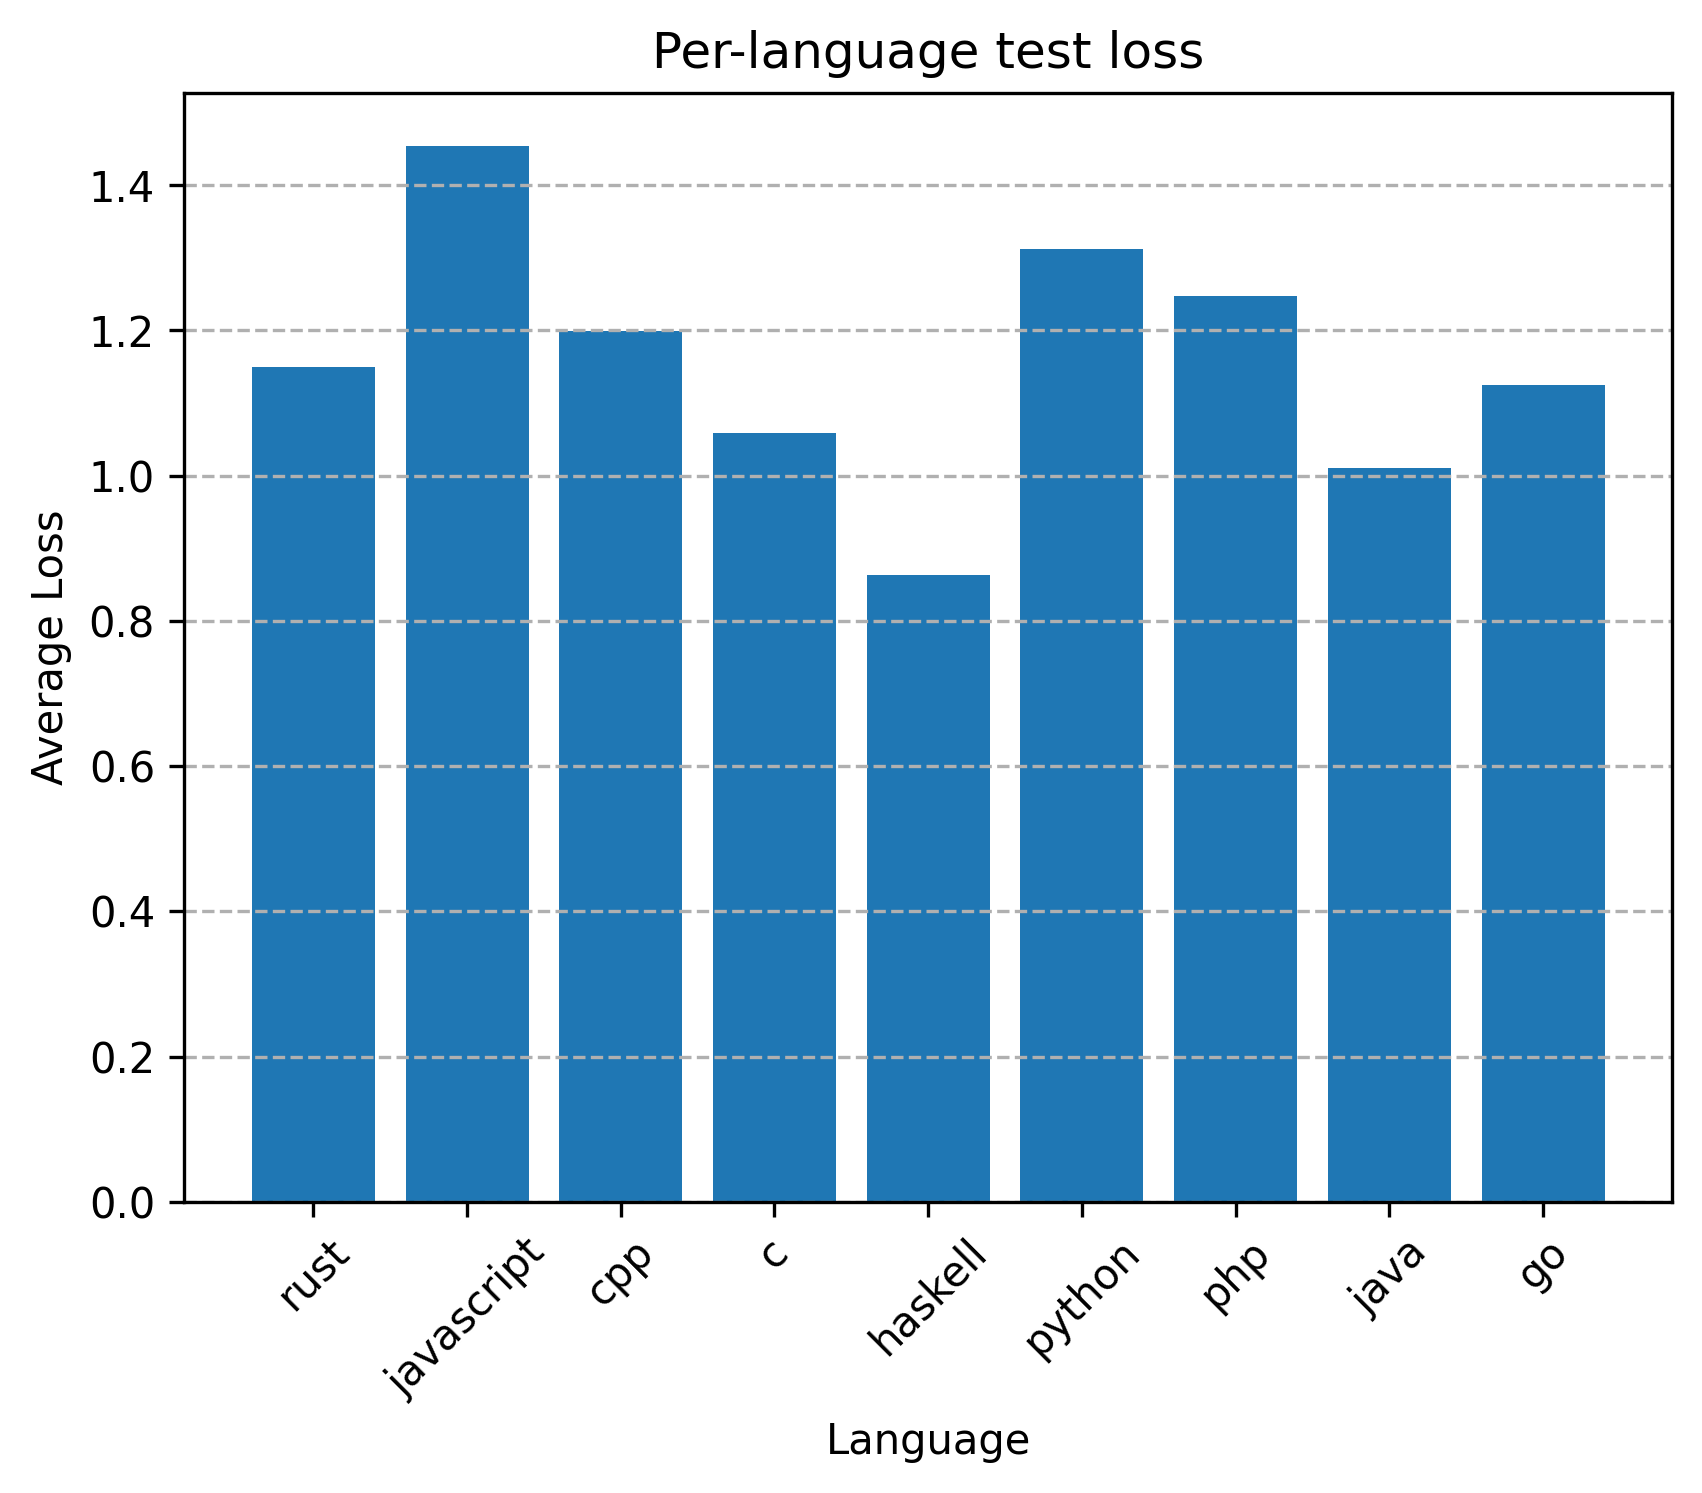

In [7]:
plt.figure(dpi=300)
plt.title("Per-language test loss")
plt.xticks(rotation=45)
plt.xlabel("Language")
plt.ylabel("Average Loss")
plt.grid(True, axis="y", which="both", linestyle="--")
plt.bar(results.keys(), results.values())
plt.show()

In [87]:
import mantel

mantel_results = defaultdict(list)


for language, loader in dataset.items():
    for i in range(10):
        idx = np.random.choice(len(loader.dataset))
        h, d, m = distance_collate([loader.dataset[idx]])
        h, d, m = h.to(device), d.to(device), m.to(device)

        with torch.no_grad():
            pred = best(h)

        pred = pred.squeeze(0).cpu().numpy()
        pred += pred.T

        pred[range(pred.shape[0]), range(pred.shape[0])] = 0

        mantel_results[language].append(
            mantel.test(pred, d.cpu().squeeze(0), perms=1000)
        )

In [88]:
{str(k): np.mean([m.r for m in mr]) for k, mr in mantel_results.items()}

{'rust': np.float64(0.7355134041778577),
 'javascript': np.float64(0.7859518736600876),
 'cpp': np.float64(0.7907742351293564),
 'c': np.float64(0.814041405916214),
 'haskell': np.float64(-201198.27956886002),
 'python': np.float64(0.7332959830760956),
 'php': np.float64(0.7890381276607513),
 'java': np.float64(0.830670964717865),
 'go': np.float64(0.904763263463974)}